In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df = pd.read_csv("../data/clean/final_df_clean.csv")

df.head()

,daytime_evening_attendance,previous_qualification_grade,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,...,unemployment_rate,inflation_rate,gdp,target,prev_qual_level,application_reordered,application_mode_group,relationship_group,course_name,nationality_group
0,1,122.0,3.0,4.0,services_sellers,unskilled,127.3,1,0,0,...,10.8,1.4,1.74,Dropout,2,5,2nd phase - general contingent,single,Animation and Multimedia Design,Portuguese
1,1,160.0,5.0,7.0,technicians,technicians,142.5,1,0,0,...,13.9,-0.3,0.79,Graduate,2,9,International student (bachelor),single,Tourism,Portuguese
2,1,122.0,1.0,1.0,unskilled,unskilled,124.8,1,0,0,...,10.8,1.4,1.74,Dropout,2,5,1st phase - general contingent,single,Communication Design,Portuguese
3,1,122.0,2.0,1.0,services_sellers,technicians,119.6,1,0,0,...,9.4,-0.8,-3.12,Graduate,2,8,2nd phase - general contingent,single,Journalism and Communication,Portuguese
4,0,100.0,1.0,2.0,unskilled,unskilled,141.5,0,0,0,...,13.9,-0.3,0.79,Graduate,2,9,Over 23 years old,married,Social Service (evening attendance),Portuguese


In [2]:
# separate enrolled students
df_enrolled = df[df["target"] == "Enrolled"].copy()

df_model = df[df["target"] != "Enrolled"].copy()

df_model["target"].value_counts()

target
Graduate    2209
Dropout     1421
Name: count, dtype: int64

In [3]:
RANDOM_STATE = 42

X = df_model.drop(columns="target")
y = df_model["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

In [4]:
#copied from the consolidated notebook
nominal_features = [
    "application_mode_group",
    "relationship_group",
    "course_name",
    "nationality_group",
    "mothers_occupation",
    "fathers_occupation"
]

ordinal_features = [
    "mothers_qualification",
    "fathers_qualification",
    "prev_qual_level"
]

binary_features = [
    "displaced",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international"
]

numerical_features = [
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "curricular_units_2nd_sem_credited",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_evaluations",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "curricular_units_2nd_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp"
]

In [5]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler())
])

nominal_pipeline = Pipeline([
    ("encoding", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

numerical_pipeline = Pipeline([
    ("scaling", MinMaxScaler())
])

In [6]:
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("nominal", nominal_pipeline, nominal_features),
    ("numerical", numerical_pipeline, numerical_features),
    ("binary", "passthrough", binary_features)
])

In [7]:
logistic_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## Logistic Regression - Model Training

In [8]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['daytime_evening_attendance','previous_qualification_grade', 'mothers_qualification',...,'relationship_group','course_name', 'nationality_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the n

## Model Evaluation - Training Data

In [9]:
y_train_pred = logistic_pipeline.predict(X_train)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [10]:
# calculate training metrics
print("Training accuracy:",
      round(accuracy_score(y_train, y_train_pred), 3))

print("Precision (Dropout):",
      round(precision_score(y_train, y_train_pred, pos_label="Dropout"), 3))

print("Recall (Dropout):",
      round(recall_score(y_train, y_train_pred, pos_label="Dropout"), 3))

print("F1 (Dropout):",
      round(f1_score(y_train, y_train_pred, pos_label="Dropout"), 3))

Training accuracy: 0.919
Precision (Dropout): 0.945
Recall (Dropout): 0.842
F1 (Dropout): 0.89


In [11]:
print(classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

     Dropout       0.94      0.84      0.89      1137
    Graduate       0.90      0.97      0.94      1767

    accuracy                           0.92      2904
   macro avg       0.92      0.90      0.91      2904
weighted avg       0.92      0.92      0.92      2904



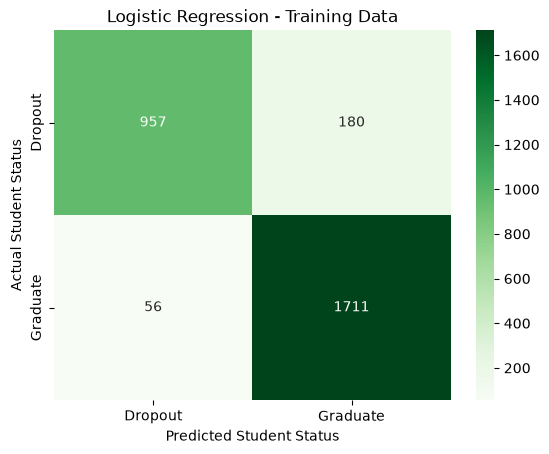

In [12]:
# confusion matrix

cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=["Dropout", "Graduate"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Dropout", "Graduate"],
    yticklabels=["Dropout", "Graduate"]
)

plt.title("Logistic Regression - Training Data")
plt.xlabel("Predicted Student Status")
plt.ylabel("Actual Student Status")
plt.show()

### Initial Training Results - Observations

- The Logistic Regression model achieved a training
  accuracy of 91.9%.
- Dropout precision is 94.5%.
- Dropout recall is 84.2%.
- The F1-score for dropout is 89.0%.
- The model identifies most dropout students in
  the training dataset.
- Cross-validation is needed to evaluate how well
  the model performs on unseen data.
- The first model uses the consolidated features
  without the newly created approval rate.